# [LAB-10] 2. 회귀모형 평가와 진단

## #01. 준비작업

### 1. 라이브러리 참조

In [50]:
from hossam import load_data
from helpers import *

import pandas as pd
import numpy as np
from pandas import DataFrame, concat
from IPython.display import display, Markdown
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

In [51]:
df0 = pd.read_excel('student_체크포인트0_기준선.xlsx')
df1 = pd.read_excel('student_체크포인트1_로그변환.xlsx')
df2 = pd.read_excel('student_체크포인트2_이상치대체.xlsx')
df3 = pd.read_excel('student_체크포인트3_다중공선성제거.xlsx')
df4 = pd.read_excel('student_체크포인트4_정규화.xlsx')

### 3. 분석 대상 정리

In [52]:
# 종속변수
target = "final_exam_score"

# 비교 대상 체크포인트 (아래로 갈수록 전처리가 하나씩 누적된다)
checkpoints = { "0_기준선": df0, "1_로그변환": df1, "2_이상치대체": df2, "3_공선성제거": df3, "4_스케일링": df4 }

# 종속변수(MEDV)에 log1p 가 적용되었는지 여부 (미적용)
log_y = { "0_기준선": False, "1_로그변환": False, "2_이상치대체": False, "3_공선성제거": False, "4_스케일링": False }

# 로그변환(log1p)이 적용된 독립변수 → 최종 모델의 회귀계수 해석에 사용한다
log1p_x = []

### 4. 종속변수 척도 확인

In [53]:
medv_scale = DataFrame()

for name in checkpoints:
    data = checkpoints[name]
    medv_scale[name] = data[target].describe()

medv_scale.round(3)

,0_기준선,1_로그변환,2_이상치대체,3_공선성제거,4_스케일링
count,2823.000,2823.000,2823.000,2823.000,2823.000
mean,54.821,54.821,54.821,54.821,54.821
std,18.723,18.723,18.723,18.723,18.723
min,0.000,0.000,0.000,0.000,0.000
25%,42.000,42.000,42.000,42.000,42.000
50%,55.000,55.000,55.000,55.000,55.000
75%,67.500,67.500,67.500,67.500,67.500
max,100.000,100.000,100.000,100.000,100.000


## #02. 체크포인트별 모델 적합 및 성능 비교

### 1. 체크포인트마다 모델을 적합(후진소거 포함)

In [54]:
fits = {}
result = []

for c in checkpoints:
    data = checkpoints[c]       # 체크포인트 데이터프레임
    log = log_y[c]              # 종속변수에 log1p가 적용되었는지 여부

    # 1) 모델 적합 (후진제거 포함)
    fit = my_ols.auto_ols(data, target, log1p_y=log, log1p_x=log1p_x,
                          backward=True, report=False, test=False)
    
    fits[c] = fit
    
    # 2) 실제값과 예측값을 원본 척도(천 달러)로 되돌린다
    if log:
        y_true = np.expm1(data[target])         # 종속변수 역변환
        y_pred = np.expm1(fit.fittedvalues)     # 예측값 역변환
    else:
        y_true = data[target]                   # 체크포인트 0 은 이미 원본 척도
        y_pred = fit.fittedvalues

    # 3) 지표를 한 행으로 정리해 저장
    result.append({
        "모델": c,
        "변수수": int(fit.df_model),        # 상수항을 제외한 독립변수 개수
        "R2(모델척도)": fit.rsquared,       # 체크포인트간 비교 불가 (참고용)
        "adj.R2": fit.rsquared_adj,         # 같은 종속변수끼리만 비교
        "AIC": fit.aic,                     # 같은 종속변수끼리만 비교 (작을수록 좋음)
        "BIC": fit.bic,                     # 같은 종속변수끼리만 비교 (작을수록 좋음)
        # 아래 세 지표는 원본 척도에서 계산하므로 체크포인트간 비교 가능
        "R2(원본척도)": r2_score(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),    # 최종 선택 기준
        "MAE": mean_absolute_error(y_true, y_pred),
    })

rdf = DataFrame(result).set_index("모델")
rdf.round(4)



유의하지 않은 독립변수 제거 → career_goal_3 (p = 0.9762)
유의하지 않은 독립변수 제거 → city_type_1 (p = 0.9384)
유의하지 않은 독립변수 제거 → caffeine_intake (p = 0.8298)
유의하지 않은 독립변수 제거 → learning_style_1 (p = 0.8271)
유의하지 않은 독립변수 제거 → gaming_hours (p = 0.8189)
유의하지 않은 독립변수 제거 → gender (p = 0.8085)
유의하지 않은 독립변수 제거 → career_goal_4 (p = 0.6831)
유의하지 않은 독립변수 제거 → career_goal_1 (p = 0.6700)
유의하지 않은 독립변수 제거 → productivity_after_midnight (p = 0.6576)
유의하지 않은 독립변수 제거 → city_type_2 (p = 0.6051)
유의하지 않은 독립변수 제거 → learning_style_2 (p = 0.5565)
유의하지 않은 독립변수 제거 → internet_quality (p = 0.2544)
유의하지 않은 독립변수 제거 → age (p = 0.2381)
유의하지 않은 독립변수 제거 → ai_tool_usage_hours (p = 0.1268)
유의하지 않은 독립변수 제거 → mental_state_2 (p = 0.0551)
유의하지 않은 독립변수 제거 → family_support (p = 0.0600)
유의하지 않은 독립변수 제거 → physical_activity_hours (p = 0.0545)

유의하지 않은 독립변수 제거 → career_goal_3 (p = 0.9762)
유의하지 않은 독립변수 제거 → city_type_1 (p = 0.9384)
유의하지 않은 독립변수 제거 → caffeine_intake (p = 0.8298)
유의하지 않은 독립변수 제거 → learning_style_1 (p = 0.8271)
유의하지 않은 독립변수 제거 → gaming_hour

,변수수,R2(모델척도),adj.R2,AIC,BIC,R2(원본척도),RMSE,MAE
모델,,,,,,,,
0_기준선,20,0.814,0.812,19848.452,19973.309,0.814,8.078,6.455
1_로그변환,20,0.814,0.812,19848.452,19973.309,0.814,8.078,6.455
2_이상치대체,20,0.814,0.812,19848.832,19973.689,0.814,8.078,6.455
3_공선성제거,20,0.814,0.812,19848.832,19973.689,0.814,8.078,6.455
4_스케일링,20,0.814,0.812,19848.832,19973.689,0.814,8.078,6.455


### 2. 최종 모델 채택

In [55]:
final_fit = fits["0_기준선"]
print(data)
print(log1p_x)

        age  gender  study_hours_per_day  deep_work_sessions  \
0     0.768       0               -0.538               1.520   
1    -0.013       0               -0.070              -0.659   
2    -1.184       0                0.198               1.520   
3    -0.013       1                0.866              -1.095   
4    -0.794       0                0.064              -0.223   
...     ...     ...                  ...                 ...   
2818  1.158       0               -1.072              -1.531   
2819 -0.013       0                0.800               1.520   
2820  1.549       0                1.268              -0.659   
2821 -0.794       1               -0.070              -1.095   
2822 -1.184       0                1.201              -1.531   

      assignment_completion_rate  attendance_percentage  social_media_hours  \
0                          1.705                 -0.311               0.572   
1                         -1.367                 -0.311              -0.2

## #03. 최종 모델 분석 결과 보고

### 1. 모형 적합도

In [56]:
display(Markdown(
    my_ols.report_fitness(final_fit, log1p_y=True, log1p_x=log1p_x)
))

**Note. n = 2823. F(20, 2802) = 612.32 p <0.001, R² = 0.814, Adj.R² = 0.812, Durbin-watson = 1.936**

log1p(final_exam_score)를 종속변수로, study_hours_per_day, deep_work_sessions, assignment_completion_rate, attendance_percentage, social_media_hours, doomscrolling_before_sleep, notification_distractions, stress_level, motivation_level, focus_score, procrastination_index, sleep_hours, financial_stress, revision_efficiency, burnout_risk, consistency_score, mental_state_1, mental_state_3, learning_style_3, career_goal_2(을)를 독립변수로 한 다중선형회귀분석 결과, 모형은 통계적으로 유의하였다.

> F(20, 2802) = 612.32, p <0.001, R² = 0.814.

즉, study_hours_per_day, deep_work_sessions, assignment_completion_rate, attendance_percentage, social_media_hours, doomscrolling_before_sleep, notification_distractions, stress_level, motivation_level, focus_score, procrastination_index, sleep_hours, financial_stress, revision_efficiency, burnout_risk, consistency_score, mental_state_1, mental_state_3, learning_style_3, career_goal_2는 log1p(final_exam_score)의 약 81.38%를 설명하는 것으로 나타났다.

### 2. 회귀계수 보고

In [57]:
my_ols.report_variables(final_fit, df1, hc3=True)

,종속변수,독립변수,B,표준오차,표준오차(HC3),β,t,t(HC3),유의확률,유의확률(HC3),공차,VIF
0,final_exam_score,consistency_score,2.117,0.054,0.055,0.323,39.448,38.762,0.000,0.000,0.990,1.010
1,final_exam_score,study_hours_per_day,3.958,0.102,0.104,0.317,38.781,37.895,0.000,0.000,0.997,1.003
2,final_exam_score,procrastination_index,-1.995,0.053,0.053,-0.307,-37.495,-37.311,0.000,0.000,0.991,1.009
3,final_exam_score,focus_score,1.964,0.054,0.054,0.300,36.701,36.181,0.000,0.000,0.991,1.009
4,final_exam_score,mental_state_1,-10.005,0.374,0.377,-0.232,-26.745,-26.570,0.000,0.000,0.882,1.133
5,final_exam_score,burnout_risk,-1.476,0.054,0.053,-0.224,-27.333,-27.653,0.000,0.000,0.992,1.008
6,final_exam_score,revision_efficiency,1.410,0.053,0.052,0.218,26.645,27.017,0.000,0.000,0.995,1.005
7,final_exam_score,motivation_level,1.411,0.054,0.054,0.215,26.308,26.081,0.000,0.000,0.993,1.007
8,final_exam_score,stress_level,-1.286,0.053,0.052,-0.199,-24.289,-24.544,0.000,0.000,0.994,1.006
9,final_exam_score,assignment_completion_rate,0.205,0.009,0.009,0.192,23.552,23.893,0.000,0.000,0.996,1.004


### 3. 영향력 순위 시각화 (표준화 계수 β)

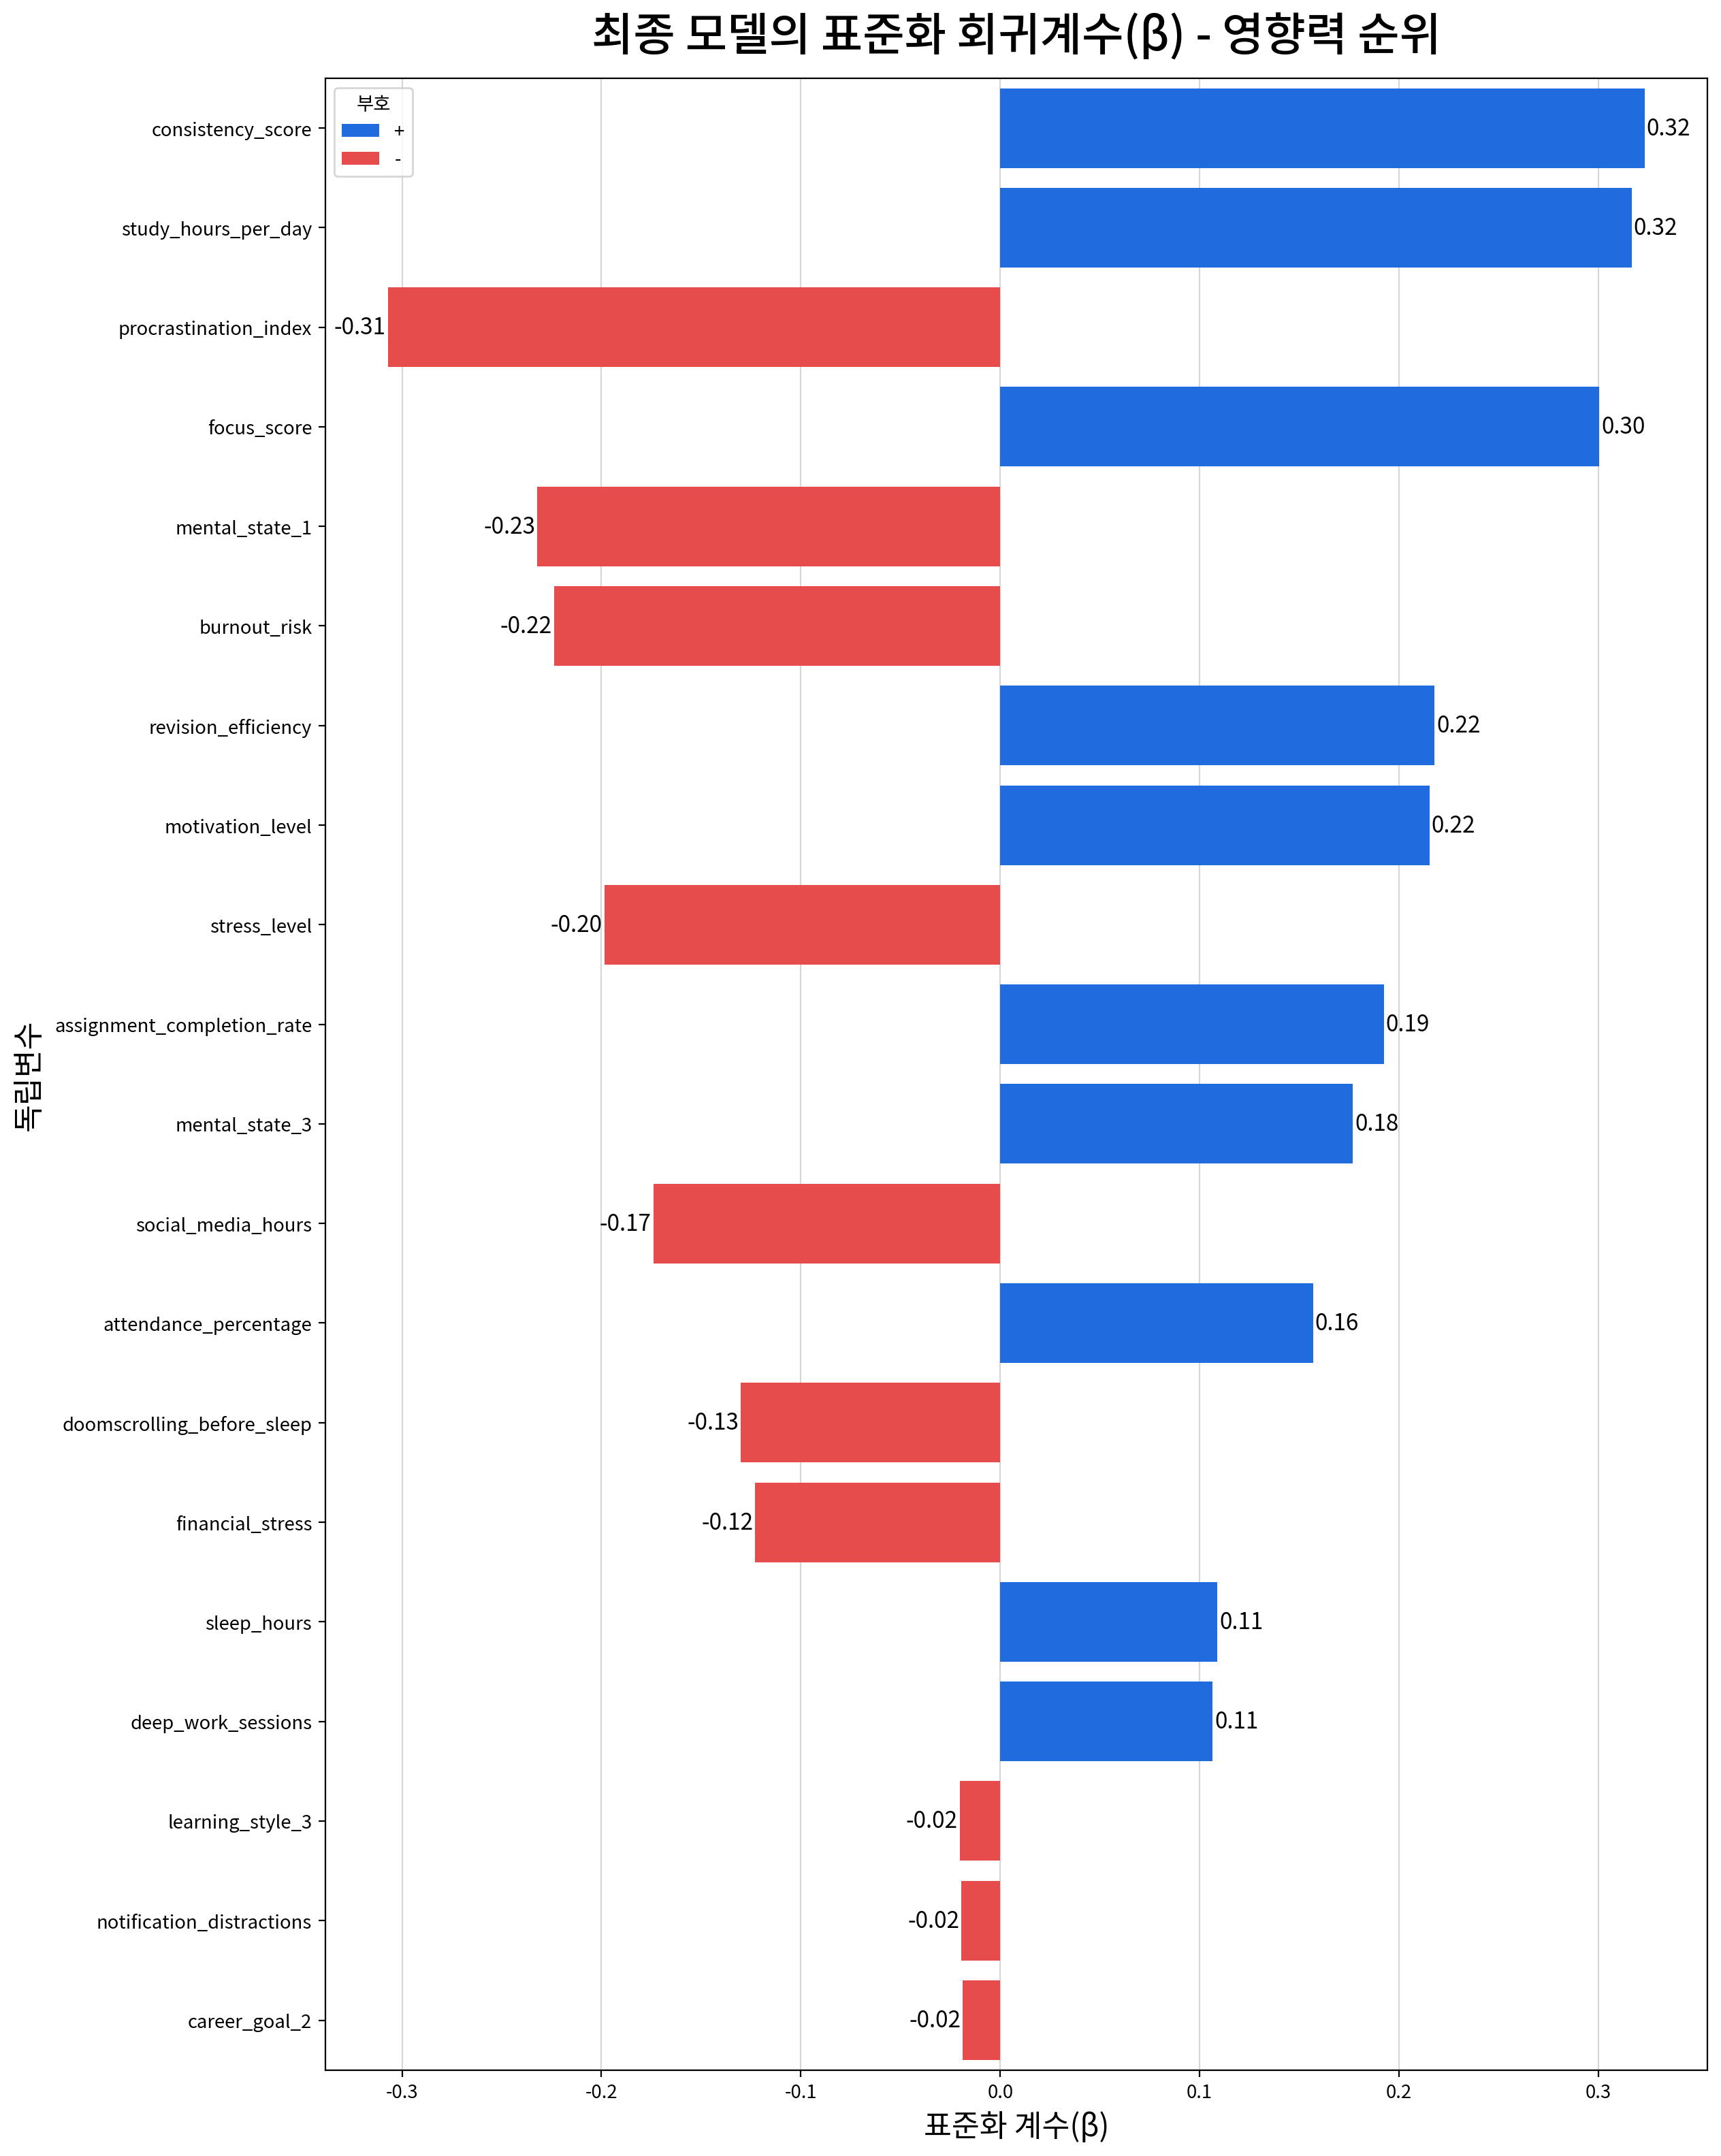

In [58]:
my_ols.plot_beta(final_fit, df1, title="최종 모델의 표준화 회귀계수(β) - 영향력 순위")

### 4. 회귀계수 해석 문장


In [59]:
display(Markdown(
    my_ols.report_variables_text(final_fit, 
                                 log1p_y=True, 
                                 log1p_x=log1p_x, 
                                 hc3=True)
))


- **study_hours_per_day**의 회귀계수는 **B = 3.96**으로 나타났으며, 이는 **final_exam_score**에 유의한 요인임을 의미한다. (**t(2802) = 37.89**, **p < .001**) 즉, study_hours_per_day가 **1 증가**할 때 **(1+final_exam_score)**는 평균적으로 약 **5137.69% 증가**하는 것으로 해석된다.
- **deep_work_sessions**의 회귀계수는 **B = 0.87**으로 나타났으며, 이는 **final_exam_score**에 유의한 요인임을 의미한다. (**t(2802) = 13.02**, **p < .001**) 즉, deep_work_sessions가 **1 증가**할 때 **(1+final_exam_score)**는 평균적으로 약 **138.66% 증가**하는 것으로 해석된다.
- **assignment_completion_rate**의 회귀계수는 **B = 0.2**으로 나타났으며, 이는 **final_exam_score**에 유의한 요인임을 의미한다. (**t(2802) = 23.89**, **p < .001**) 즉, assignment_completion_rate가 **1 증가**할 때 **(1+final_exam_score)**는 평균적으로 약 **22.74% 증가**하는 것으로 해석된다.
- **attendance_percentage**의 회귀계수는 **B = 0.2**으로 나타났으며, 이는 **final_exam_score**에 유의한 요인임을 의미한다. (**t(2802) = 18.91**, **p < .001**) 즉, attendance_percentage가 **1 증가**할 때 **(1+final_exam_score)**는 평균적으로 약 **22.53% 증가**하는 것으로 해석된다.
- **social_media_hours**의 회귀계수는 **B = -2.16**으로 나타났으며, 이는 **final_exam_score**에 유의한 요인임을 의미한다. (**t(2802) = -21.14**, **p < .001**) 즉, social_media_hours가 **1 증가**할 때 **(1+final_exam_score)**는 평균적으로 약 **88.42% 감소**하는 것으로 해석된다.
- **doomscrolling_before_sleep**의 회귀계수는 **B = -4.87**으로 나타났으며, 이는 **final_exam_score**에 유의한 요인임을 의미한다. (**t(2802) = -15.87**, **p < .001**) 즉, doomscrolling_before_sleep가 **1 증가**할 때 **(1+final_exam_score)**는 평균적으로 약 **99.23% 감소**하는 것으로 해석된다.
- **notification_distractions**의 회귀계수는 **B = -0.01**으로 나타났으며, 이는 **final_exam_score**에 유의한 요인임을 의미한다. (**t(2802) = -2.37**, **p = .018**) 즉, notification_distractions가 **1 증가**할 때 **(1+final_exam_score)**는 평균적으로 약 **1.10% 감소**하는 것으로 해석된다.
- **stress_level**의 회귀계수는 **B = -1.29**으로 나타났으며, 이는 **final_exam_score**에 유의한 요인임을 의미한다. (**t(2802) = -24.54**, **p < .001**) 즉, stress_level가 **1 증가**할 때 **(1+final_exam_score)**는 평균적으로 약 **72.37% 감소**하는 것으로 해석된다.
- **motivation_level**의 회귀계수는 **B = 1.41**으로 나타났으며, 이는 **final_exam_score**에 유의한 요인임을 의미한다. (**t(2802) = 26.08**, **p < .001**) 즉, motivation_level가 **1 증가**할 때 **(1+final_exam_score)**는 평균적으로 약 **309.94% 증가**하는 것으로 해석된다.
- **focus_score**의 회귀계수는 **B = 1.96**으로 나타났으며, 이는 **final_exam_score**에 유의한 요인임을 의미한다. (**t(2802) = 36.18**, **p < .001**) 즉, focus_score가 **1 증가**할 때 **(1+final_exam_score)**는 평균적으로 약 **613.11% 증가**하는 것으로 해석된다.
- **procrastination_index**의 회귀계수는 **B = -2.0**으로 나타났으며, 이는 **final_exam_score**에 유의한 요인임을 의미한다. (**t(2802) = -37.31**, **p < .001**) 즉, procrastination_index가 **1 증가**할 때 **(1+final_exam_score)**는 평균적으로 약 **86.40% 감소**하는 것으로 해석된다.
- **sleep_hours**의 회귀계수는 **B = 1.7**으로 나타났으며, 이는 **final_exam_score**에 유의한 요인임을 의미한다. (**t(2802) = 13.38**, **p < .001**) 즉, sleep_hours가 **1 증가**할 때 **(1+final_exam_score)**는 평균적으로 약 **448.94% 증가**하는 것으로 해석된다.
- **financial_stress**의 회귀계수는 **B = -0.8**으로 나타났으며, 이는 **final_exam_score**에 유의한 요인임을 의미한다. (**t(2802) = -14.88**, **p < .001**) 즉, financial_stress가 **1 증가**할 때 **(1+final_exam_score)**는 평균적으로 약 **55.25% 감소**하는 것으로 해석된다.
- **revision_efficiency**의 회귀계수는 **B = 1.41**으로 나타났으며, 이는 **final_exam_score**에 유의한 요인임을 의미한다. (**t(2802) = 27.02**, **p < .001**) 즉, revision_efficiency가 **1 증가**할 때 **(1+final_exam_score)**는 평균적으로 약 **309.75% 증가**하는 것으로 해석된다.
- **burnout_risk**의 회귀계수는 **B = -1.48**으로 나타났으며, 이는 **final_exam_score**에 유의한 요인임을 의미한다. (**t(2802) = -27.65**, **p < .001**) 즉, burnout_risk가 **1 증가**할 때 **(1+final_exam_score)**는 평균적으로 약 **77.14% 감소**하는 것으로 해석된다.
- **consistency_score**의 회귀계수는 **B = 2.12**으로 나타났으며, 이는 **final_exam_score**에 유의한 요인임을 의미한다. (**t(2802) = 38.76**, **p < .001**) 즉, consistency_score가 **1 증가**할 때 **(1+final_exam_score)**는 평균적으로 약 **730.32% 증가**하는 것으로 해석된다.
- **mental_state_1**의 회귀계수는 **B = -10.01**으로 나타났으며, 이는 **final_exam_score**에 유의한 요인임을 의미한다. (**t(2802) = -26.57**, **p < .001**) 즉, mental_state_1가 **1 증가**할 때 **(1+final_exam_score)**는 평균적으로 약 **100.00% 감소**하는 것으로 해석된다.
- **mental_state_3**의 회귀계수는 **B = 7.7**으로 나타났으며, 이는 **final_exam_score**에 유의한 요인임을 의미한다. (**t(2802) = 20.16**, **p < .001**) 즉, mental_state_3가 **1 증가**할 때 **(1+final_exam_score)**는 평균적으로 약 **220397.56% 증가**하는 것으로 해석된다.
- **learning_style_3**의 회귀계수는 **B = -0.86**으로 나타났으며, 이는 **final_exam_score**에 유의한 요인임을 의미한다. (**t(2802) = -2.56**, **p = .010**) 즉, learning_style_3가 **1 증가**할 때 **(1+final_exam_score)**는 평균적으로 약 **57.70% 감소**하는 것으로 해석된다.
- **career_goal_2**의 회귀계수는 **B = -0.88**으로 나타났으며, 이는 **final_exam_score**에 유의한 요인임을 의미한다. (**t(2802) = -2.24**, **p = .025**) 즉, career_goal_2가 **1 증가**할 때 **(1+final_exam_score)**는 평균적으로 약 **58.60% 감소**하는 것으로 해석된다.

> ※ 위 **t**와 **유의확률**은 등분산 가정이 충족되지 않은 경우를 대비해 **HC3 로버스트 표준오차**로 계산한 값이다. 회귀계수(B)와 효과 크기 해석은 일반 OLS와 동일하며, 표준오차만 이분산에 강건하게 보정되어 유의성 판정이 달라질 수 있다.

> ※ **log1p**(=ln(1+·))의 % 해석은 변수 자체가 아니라 **(1+변수)** 기준이며, 값이 클 때만 위 근사가 성립한다(0·작은 값 구간에서는 원본처럼 동작해 부정확). 이 구간에서는 부호·유의성 중심으로 해석하거나 예측값을 expm1로 원 척도에서 비교한다.

## #04. 최종 모델의 회귀분석 가정 검정

### 1. 선형성 검정

,statistic,p-value,linearity,result
Ramsey RESET,0.057,0.812,True,귀무가설 채택 → 선형성 위배 근거 없음


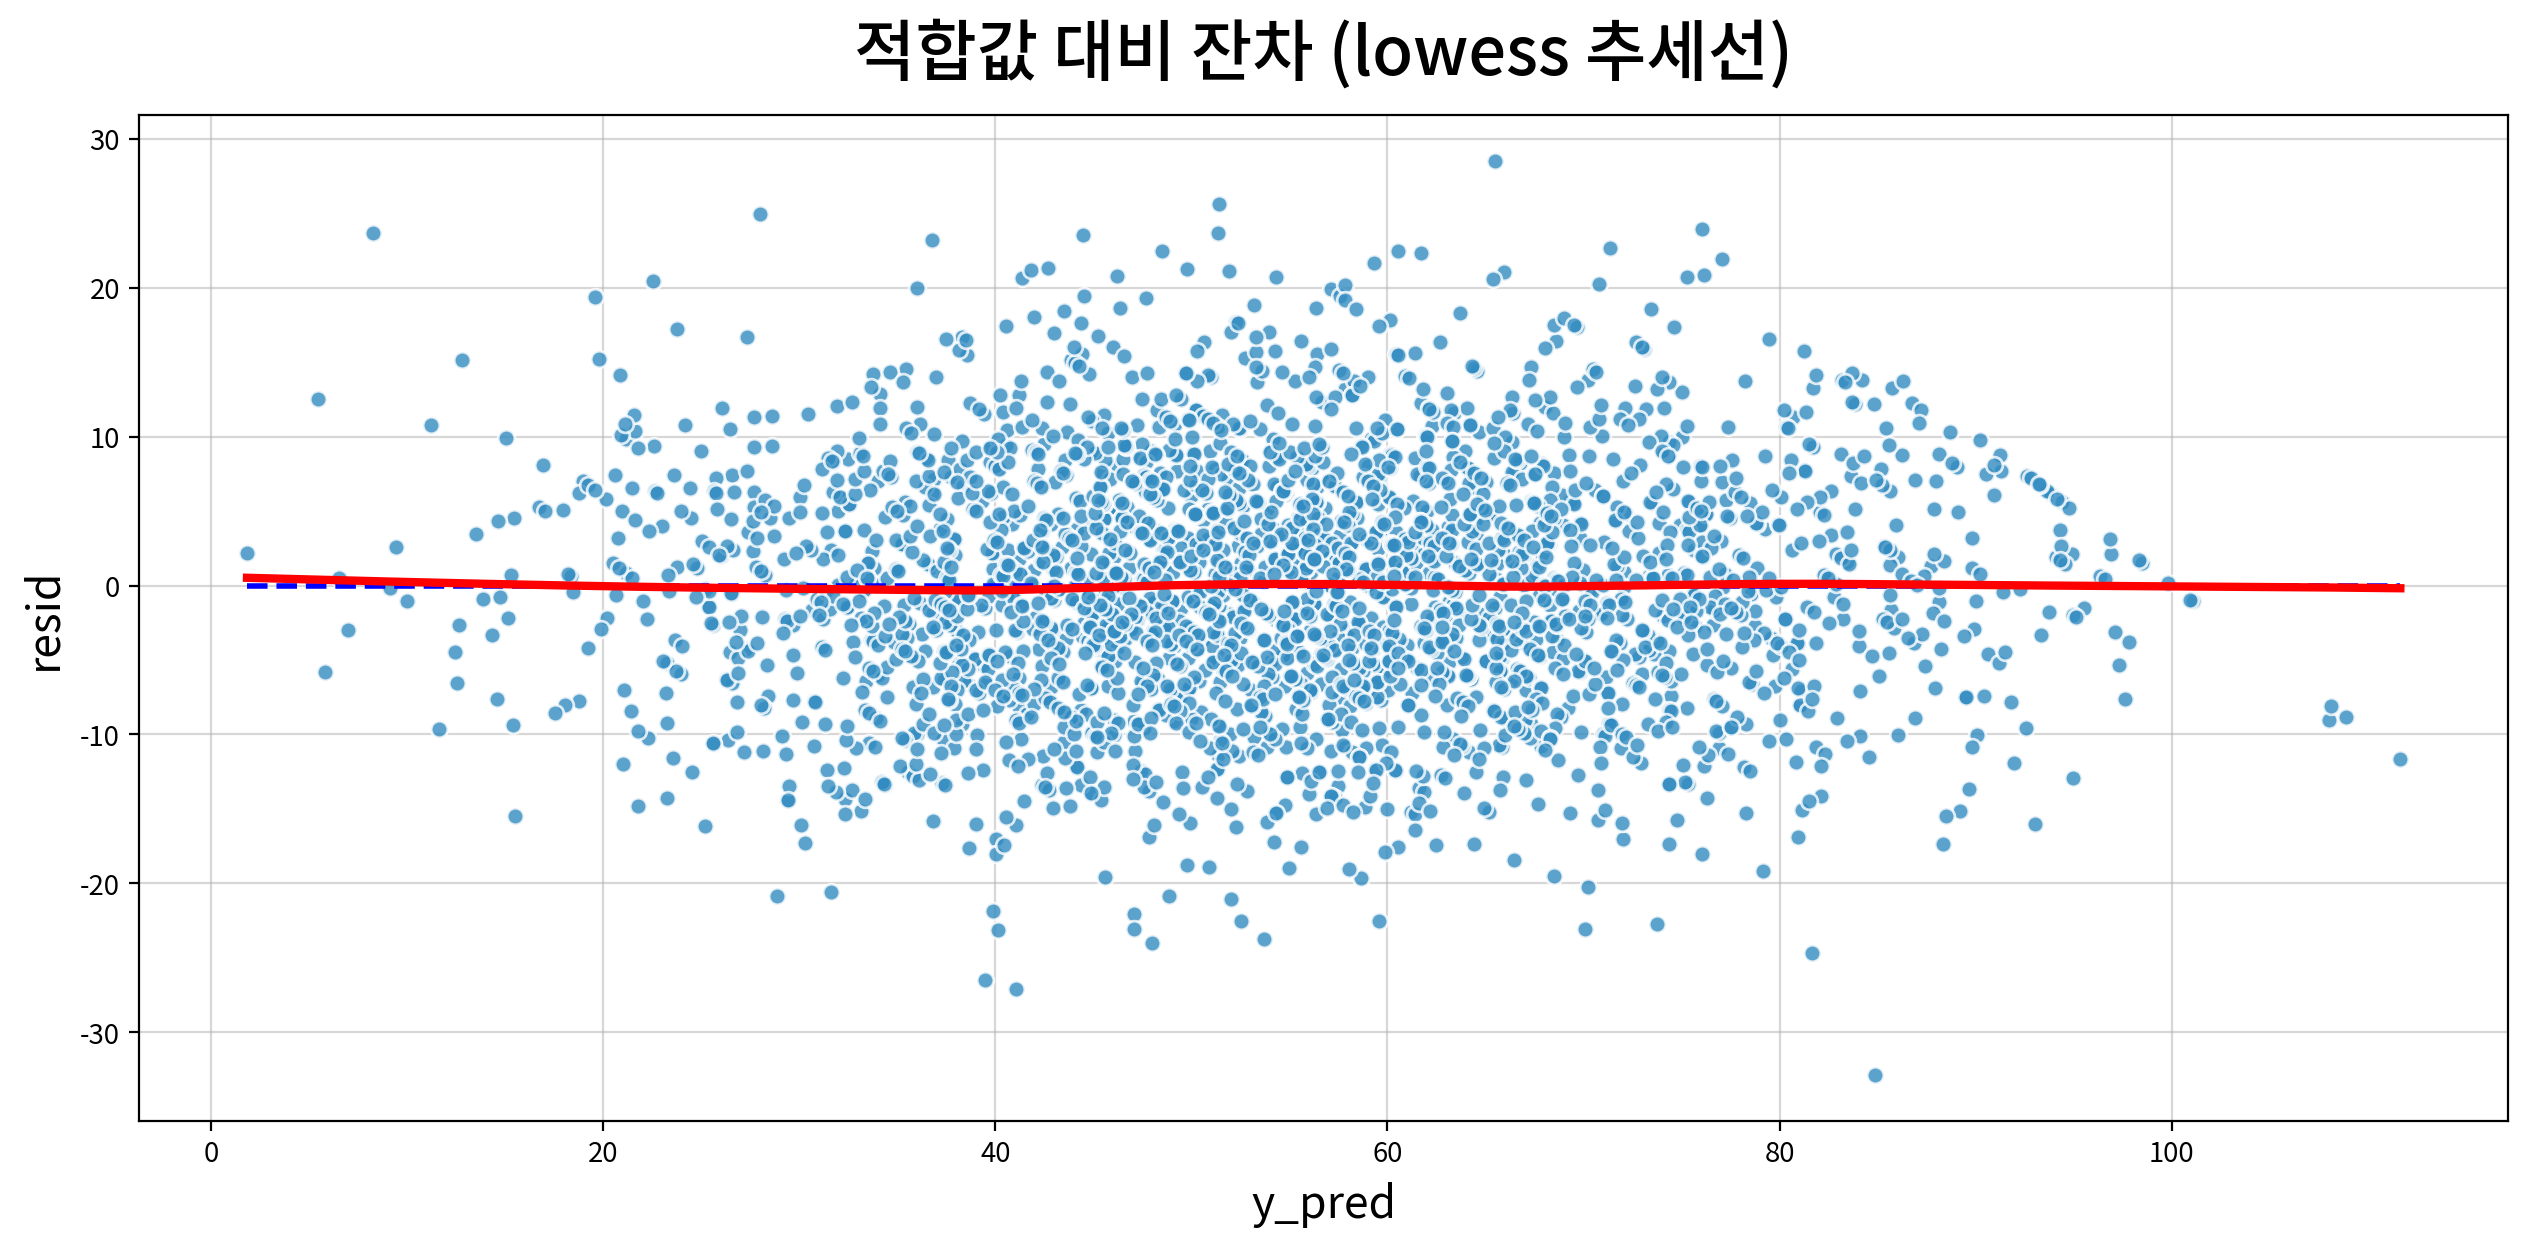

In [60]:
my_ols.test_linear(final_fit, plot=True,
                   title="적합값 대비 잔차 (lowess 추세선)")

### 2. 정규성 검정

,statistic,p-value,normality,result
Kolmogorov-Smirnov,0.013,0.762,True,귀무가설 채택 → 정규성 만족


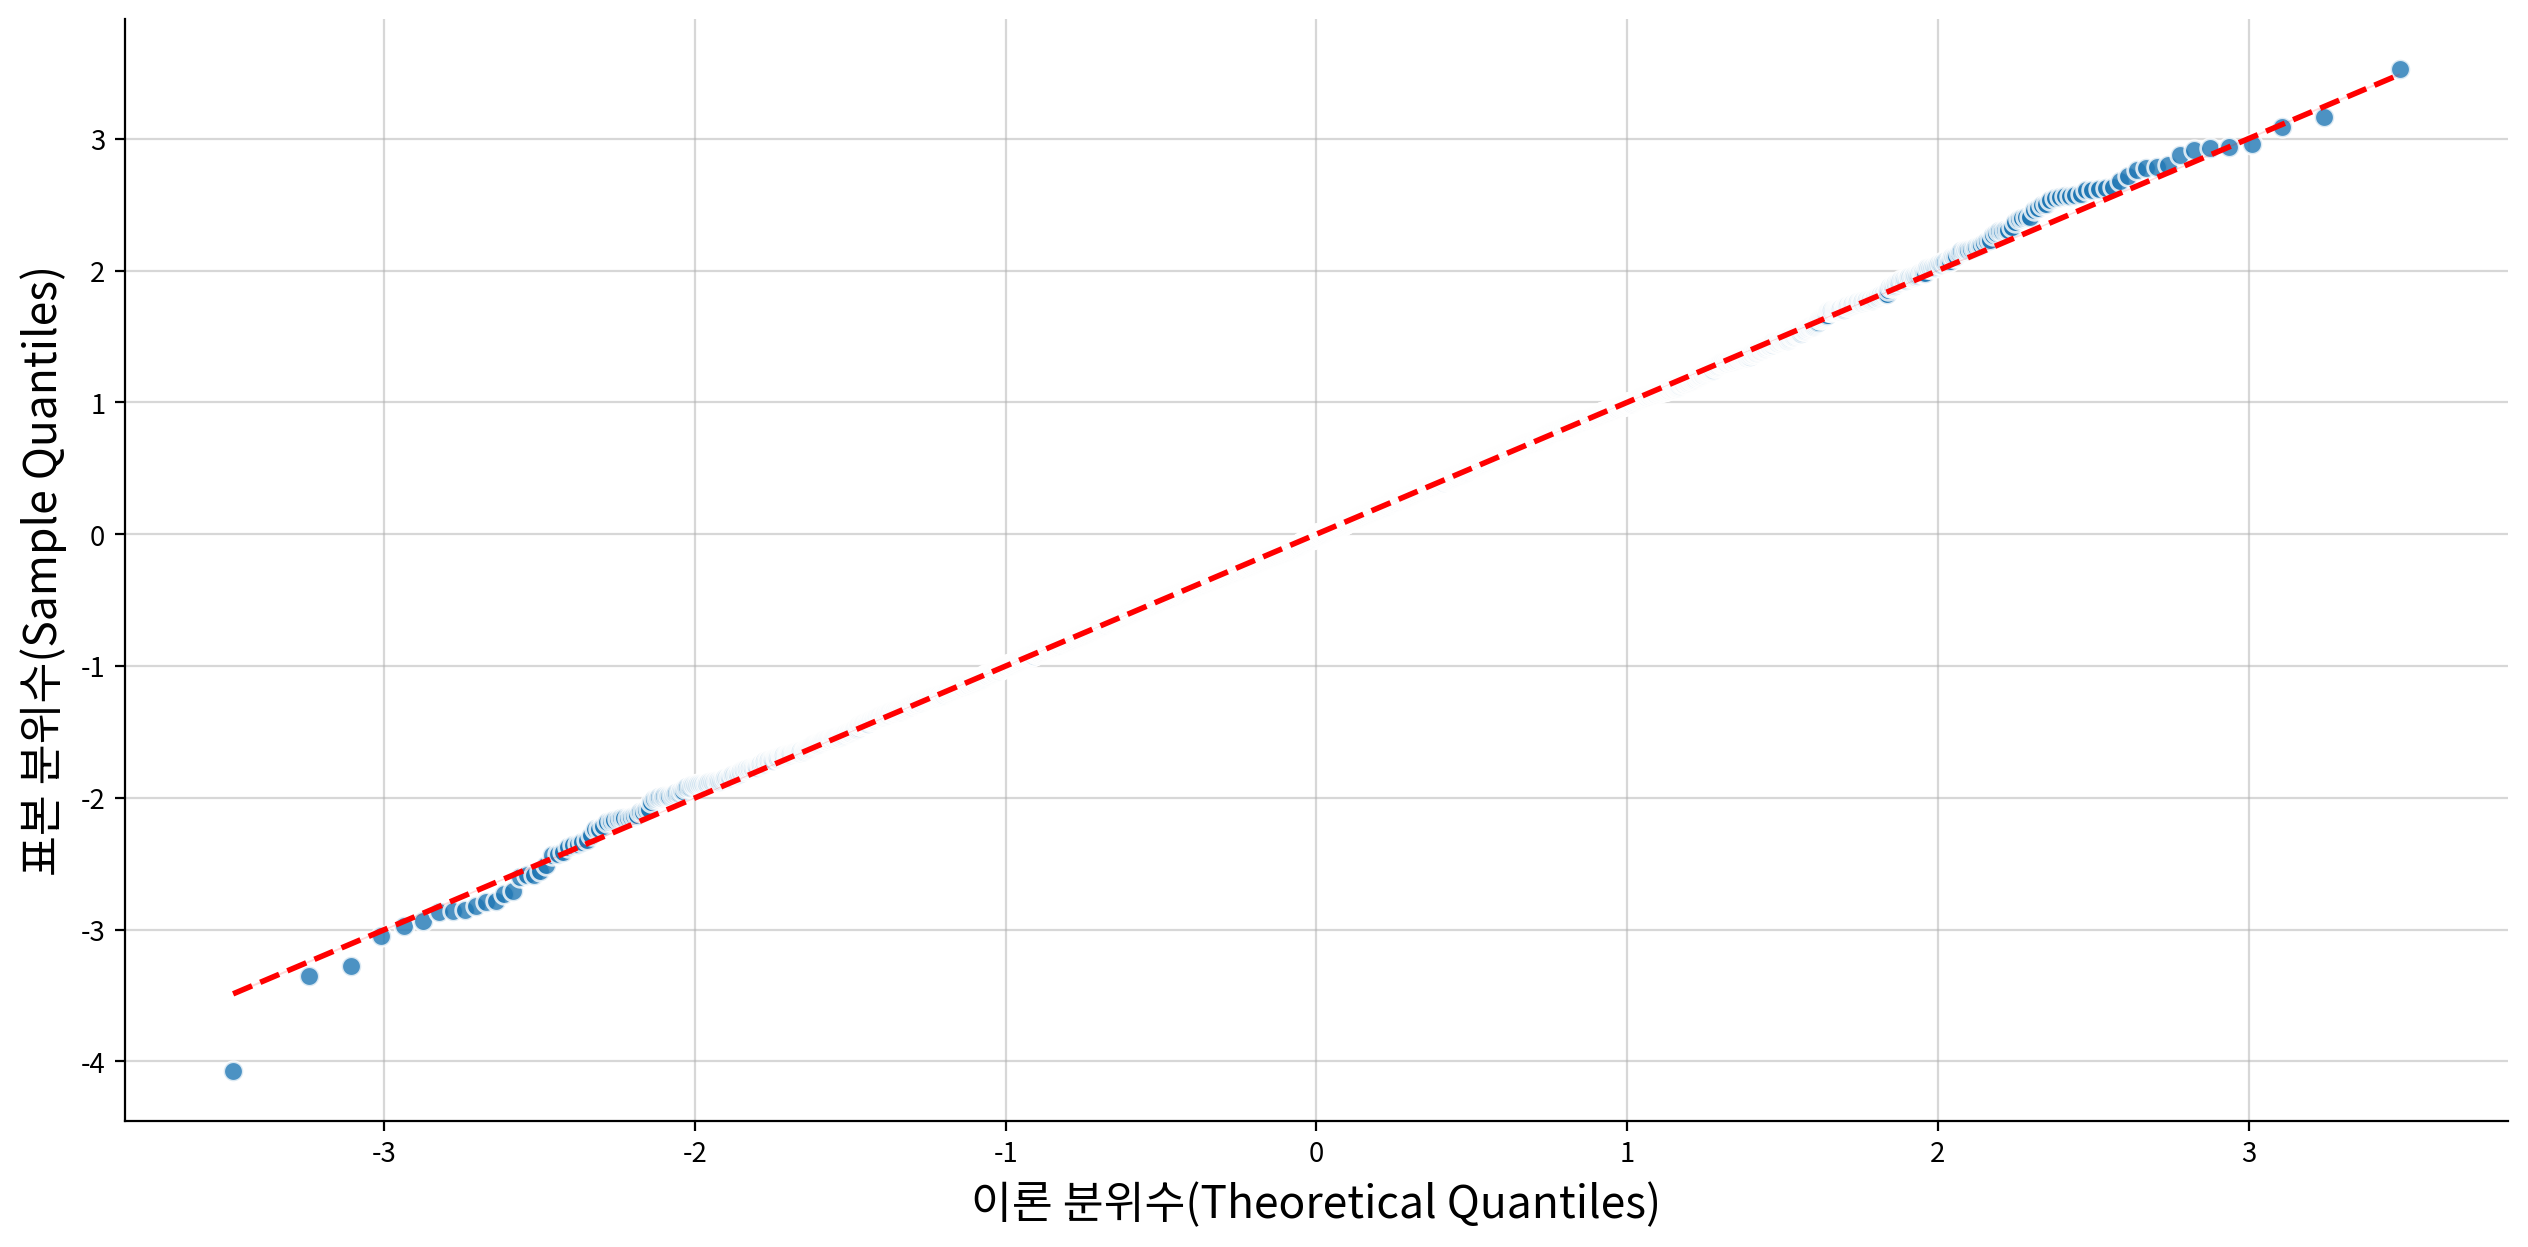

,기대(%),허용범위(%),실제(%),판정
구간,,,,
±1√MSE,68.000,66 ~ 70,68.900,충족
±2√MSE,95.000,94 ~ 96,95.860,위배
±3√MSE,99.700,99 ~ 100,99.750,충족


√MSE = 8.11 · 구간 규칙 판정: 정규성 위배


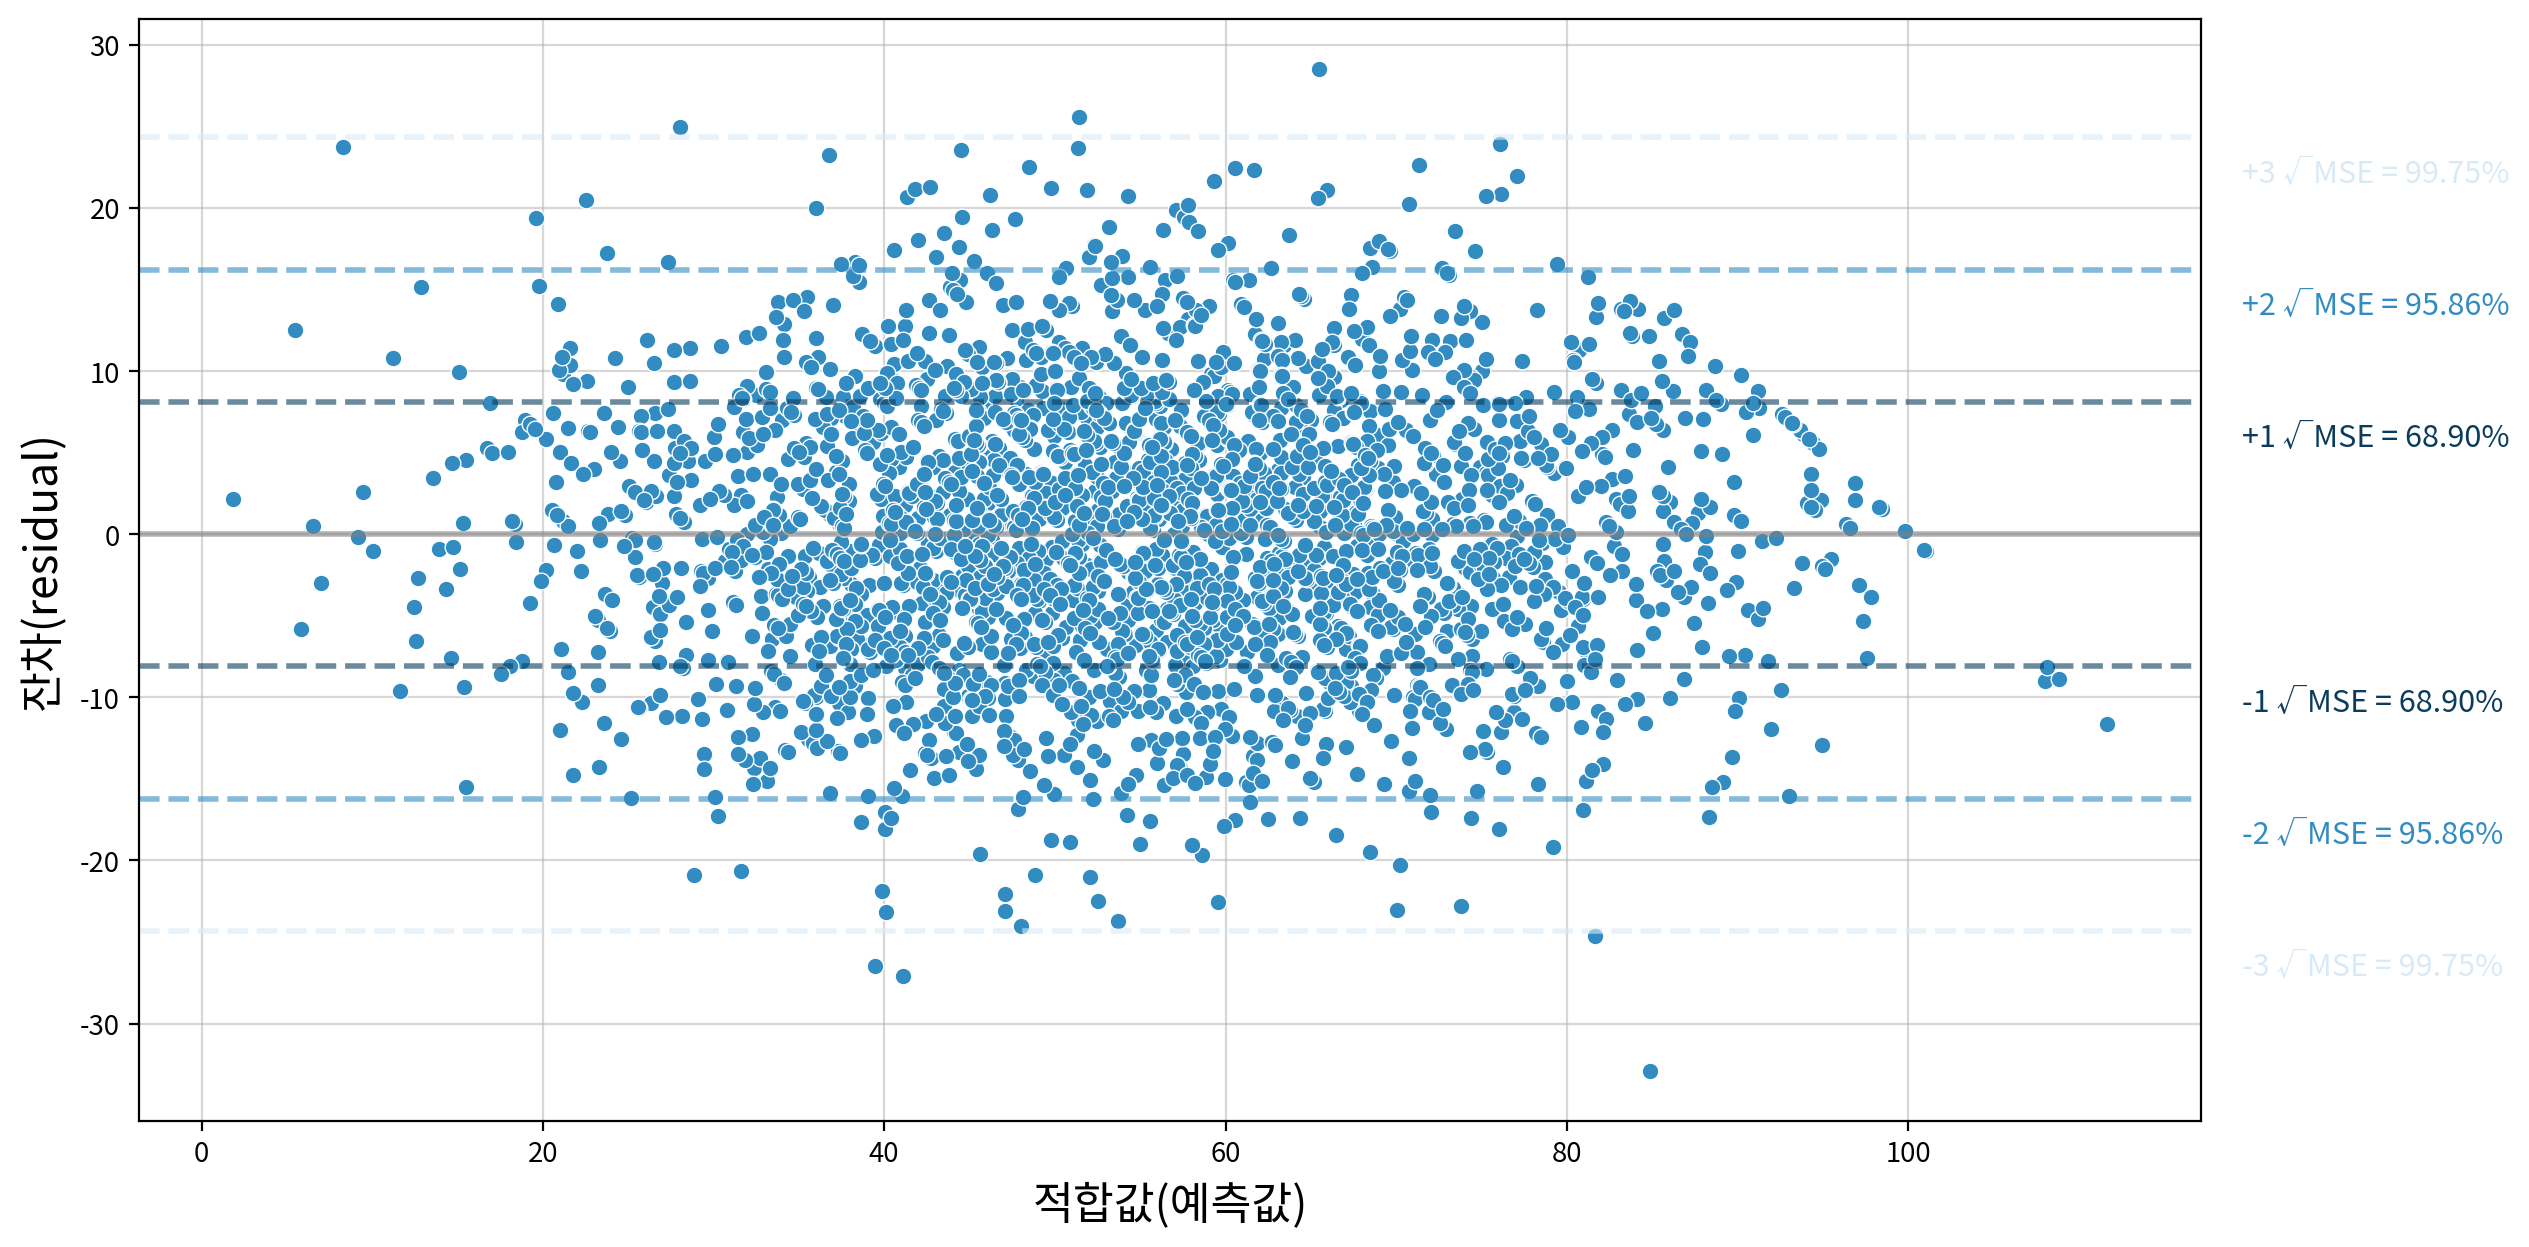

In [61]:
my_ols.test_normal(final_fit, plot=True)

### 3. 등분산성 검정

In [62]:
my_ols.test_equalvar(final_fit)

,LM statistic,LM p-value,F statistic,F p-value,homoscedasticity,result
Breusch-Pagan,21.197,0.386,1.060,0.386,True,귀무가설 채택 → 등분산성 만족


### 4. 독립성 검정

In [63]:
my_ols.test_independent(final_fit)

,statistic,independence,result
Durbin-Watson,1.936,True,독립성 만족
